In [49]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split, Subset

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

from kaggle.api.kaggle_api_extended import KaggleApi

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [50]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


In [51]:
load_dotenv()

print(os.environ["KAGGLE_API_TOKEN"][:4])

KGAT


In [52]:
api = KaggleApi()
api.authenticate()

output_dir = r"E:\kdf\machine_learning\resource"
# output_dir = r"C:\kdt_0900_pjh\machine_learning\resource\datasets"
os.makedirs(output_dir, exist_ok=True)
# api.dataset_download_files(r"asdasdasasdas/garbage-classification", path=output_dir, unzip=True)

print("다운로드 완료")

다운로드 완료


## Garbage Classification(위성에서 찍은 지형 이미지 분류)
| 파일명 | 설명 | 이미지수|
| :--- | :--- | :--- |
| cardboard | 판지 | 403장 |
| glass | 유리 | 501장 |
| metal | 금속 | 410장 |
| paper | 종이 | 594장 |
| plastic | 플라스틱 | 482장 |
| trash | 일반 쓰레기 | 137장 |

In [53]:
folder_name = r"Garbage_classification"
file_path = os.path.join(output_dir, folder_name)

base_dataset = ImageFolder(root=file_path, transform=None)

class_dict = dict(enumerate(base_dataset.classes))

In [54]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [55]:
# Dataset객체를 넘기면 sklearn이 인덱싱을 하기위해 base_dataset 0~2527까지 전부 호출하게 되는데
# 시간도 오래걸리고 튜플에 담긴 리스트로 나오게 된다.

# train_datas, test_datas = train_test_split(
#     base_dataset,
#     test_size=0.2,
#     shuffle=True,
#     random_state=42
# )

train_idx, test_idx = train_test_split(
    range(len(base_dataset)),
    test_size=0.2, 
    stratify=base_dataset.targets, 
    random_state=42
)

train_subset = Subset(base_dataset, train_idx) 
test_subset = Subset(base_dataset, test_idx)

len(train_subset), len(test_subset)

(2021, 506)

In [56]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [57]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)  
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [58]:
imgs, labels = next(iter(train_dataloader))

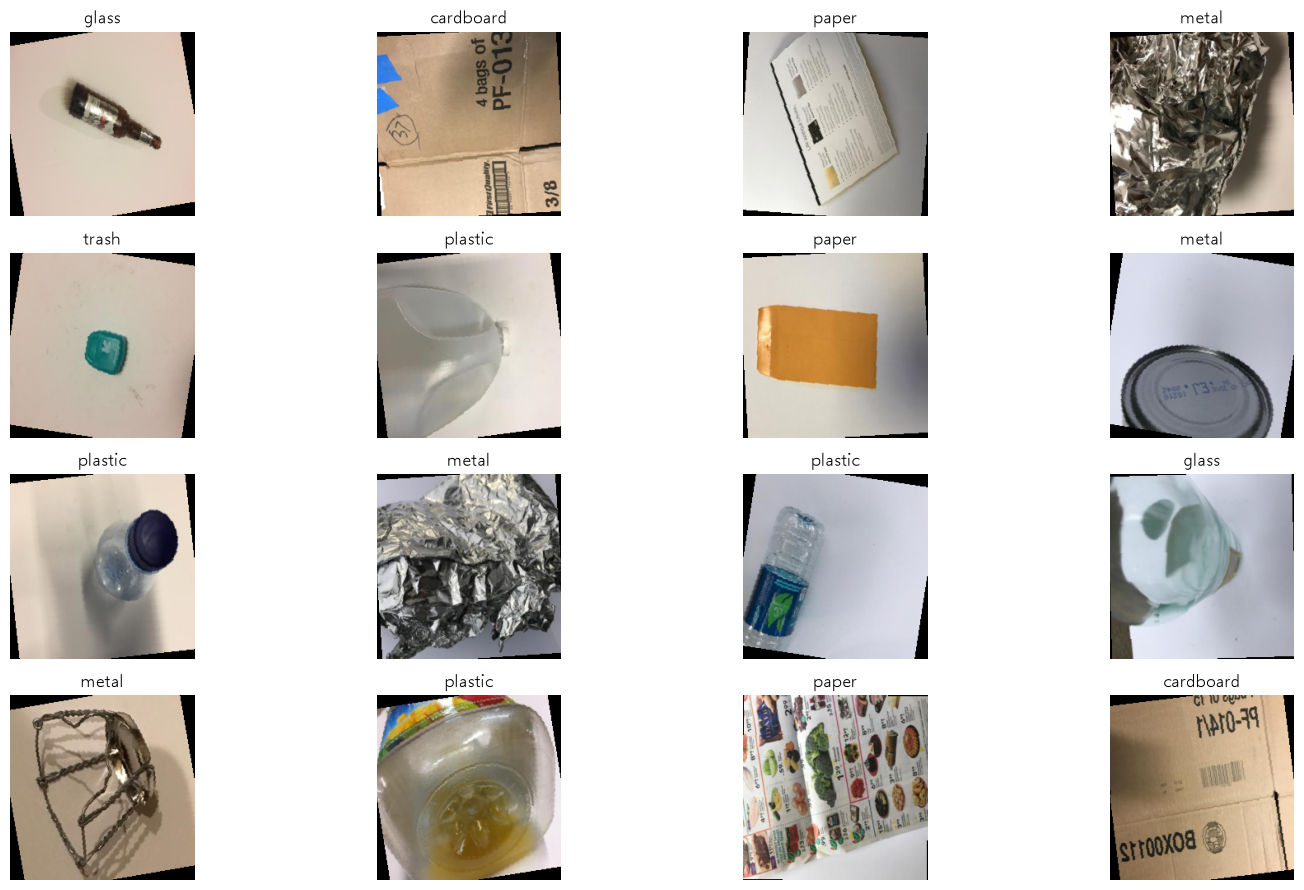

In [59]:
fig, axes = plt.subplots(4, 4, figsize=(16, 9))

# RGB 텐서가 (3, 224, 224)인데 imshow는 (224, 224, 3)으로 채널이 뒤에 있어야하기 때문에 permute를 활용하여 순서를 바꿔준다.
mean_view = torch.tensor(mean).view(3, 1, 1)
std_view = torch.tensor(std).view(3, 1, 1)

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [60]:
base_path = r"E:\kdf\machine_learning\resource"
model_weights_path = os.path.join(base_path, "weights")
os.makedirs(model_weights_path, exist_ok=True)

# PyTorch Hub 기본 캐시 경로를 변경
torch.hub.set_dir(model_weights_path)

model = models.resnet18(weights="IMAGENET1K_V1").to(device)

In [61]:
for param in model.parameters():
    param.requires_grad = False

In [62]:
model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 6),
).to(device)

In [63]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device):
    model.train()
    sum_loss = 0.0
    sum_acc = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        batch_loss = 0.0
        
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_loss += batch_loss

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_acc += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] | [Batch Loss: {batch_loss:.4f}] | [Batch Accuracy: {acc:.2f}]")

    avg_loss = sum_loss / len(dataloader)
    avg_acc = sum_acc / len(dataloader)

    return avg_loss, avg_acc

In [64]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device):
    model.eval()
    sum_loss = 0.0
    sum_acc = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_loss += loss.item()

        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_acc += acc

    avg_loss = sum_loss / len(dataloader)
    avg_acc = sum_acc / len(dataloader)

    return avg_loss, avg_acc

In [65]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [], 
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }
    best_val_acc = 0.0

    # 학습
    print(f"===================== {model_name} 학습 시작 =====================")
    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}")
        print(f"[Epoch: {epoch + 1}/{epochs}] | Vaildation Loss: {val_loss:.4f} | Vaildation Accuracy: {val_acc:.2f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"===================== {model_name} 학습 종료 =====================")
    return history

In [66]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [67]:
history = train_model_multiclass(
    model=model,
    model_name="Resnet-Multiclass",
    train_loader=train_dataloader,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=5,
    device=device,
    save_base_dir=os.path.join(base_path, r"weights")
)

===================== Resnet-Multiclass 학습 시작 =====================
[Batch 20/64] | [Batch Loss: 1.2570] | [Batch Accuracy: 59.38]
[Batch 40/64] | [Batch Loss: 0.9263] | [Batch Accuracy: 81.25]
[Batch 60/64] | [Batch Loss: 1.0256] | [Batch Accuracy: 62.50]
[Epoch: 1/5] | Train Loss: 1.2644 | Train Accuracy: 51.93
[Epoch: 1/5] | Vaildation Loss: 0.8978 | Vaildation Accuracy: 70.93
[Batch 20/64] | [Batch Loss: 0.7101] | [Batch Accuracy: 78.12]
[Batch 40/64] | [Batch Loss: 0.8079] | [Batch Accuracy: 71.88]
[Batch 60/64] | [Batch Loss: 1.2913] | [Batch Accuracy: 53.12]
[Epoch: 2/5] | Train Loss: 0.8815 | Train Accuracy: 68.40
[Epoch: 2/5] | Vaildation Loss: 0.7200 | Vaildation Accuracy: 75.71
[Batch 20/64] | [Batch Loss: 0.6429] | [Batch Accuracy: 81.25]
[Batch 40/64] | [Batch Loss: 0.7139] | [Batch Accuracy: 81.25]
[Batch 60/64] | [Batch Loss: 0.6684] | [Batch Accuracy: 84.38]
[Epoch: 3/5] | Train Loss: 0.7883 | Train Accuracy: 71.47
[Epoch: 3/5] | Vaildation Loss: 0.6510 | Vaildation Acc

In [68]:
base_path

'E:\\kdf\\machine_learning\\resource'

Test Loss: 0.6304  Test Accuracy: 78.68%

              precision    recall  f1-score   support

   cardboard       0.99      0.81      0.89        81
       glass       0.72      0.80      0.76       100
       metal       0.68      0.84      0.75        82
       paper       0.83      0.87      0.85       119
     plastic       0.79      0.69      0.74        97
       trash       0.71      0.44      0.55        27

    accuracy                           0.79       506
   macro avg       0.79      0.74      0.76       506
weighted avg       0.80      0.79      0.79       506



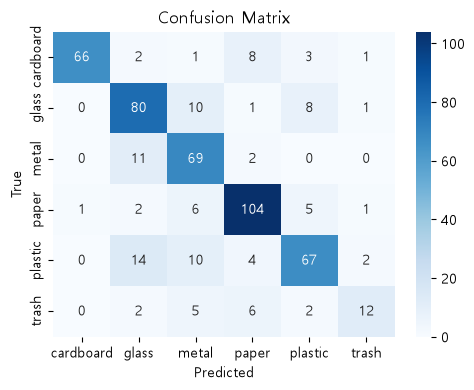

In [69]:
# [추가] 최종 평가 - test 셋은 여기서 처음, 그리고 한 번만 사용
model.eval()

y_true_all = []
y_pred_all = []

with torch.no_grad():
    for batch_imgs, batch_labels in test_dataloader:
        outputs = model(batch_imgs.to(device))
        _, batch_preds = outputs.max(1)
        y_pred_all.extend(batch_preds.cpu().tolist())
        y_true_all.extend(batch_labels.tolist())

test_loss, test_acc = evaluate_multiclass(model, test_dataloader, criterion, device)
print(f"Test Loss: {test_loss:.4f}  Test Accuracy: {test_acc:.2f}%\n")

# [추가] 클래스별 정밀도/재현율 - 정확도 숫자 하나로는 어떤 도형을 틀리는지 알 수 없다
target_names = [class_dict[i] for i in range(len(class_dict))]
print(classification_report(y_true_all, y_pred_all, target_names=target_names))

# [추가] 혼동 행렬 - 어떤 클래스를 어떤 클래스로 착각하는지
cm = confusion_matrix(y_true_all, y_pred_all)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

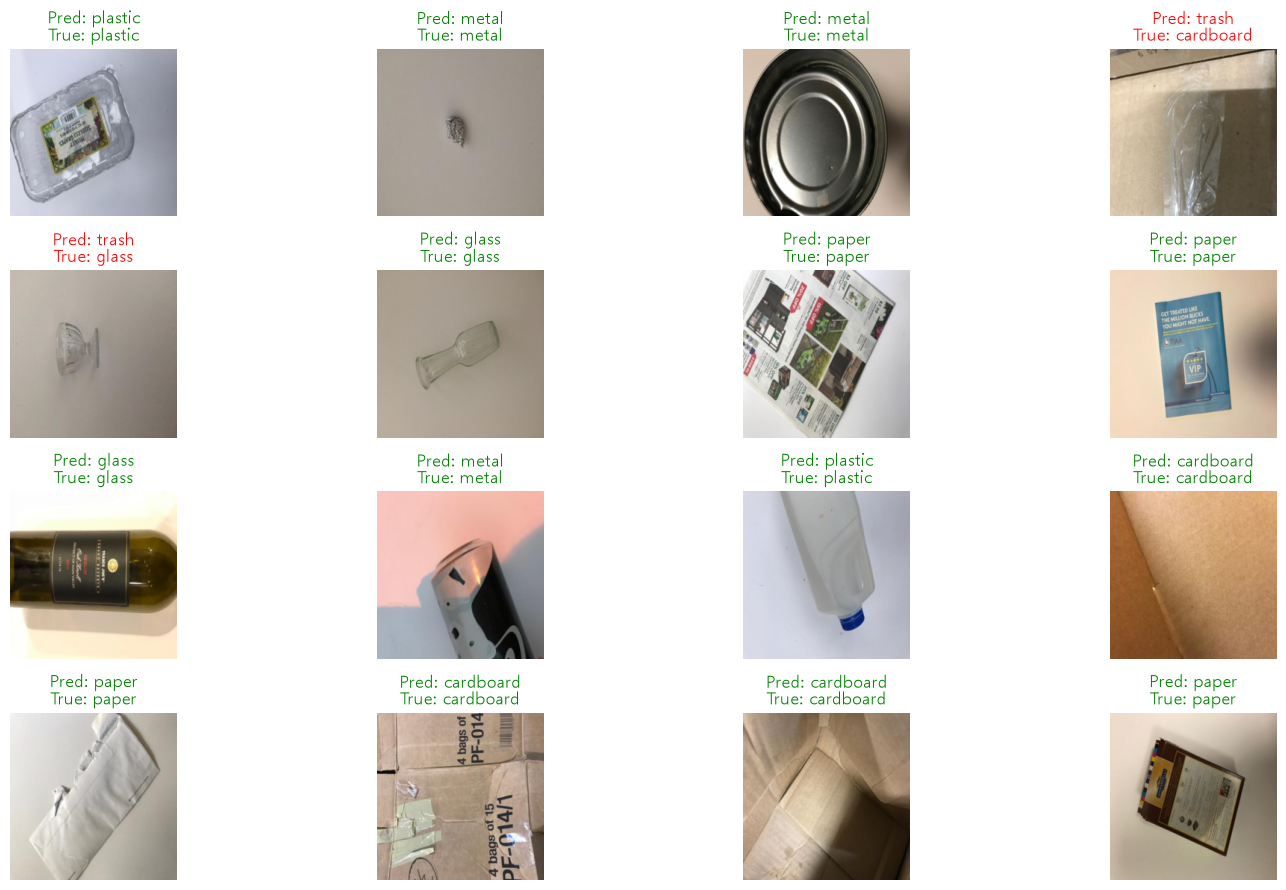

In [29]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1) # _는 첫번째 변수는 사용하지 않겠다는 뜻

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 4, figsize=(16, 9))   # [수정] figsize (16,8) -> (14,14) : 6x6인데 세로가 짧아 제목이 겹침

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    # [수정] 역정규화 추가 : Normalize(0.5, 0.5)로 [-1, 1] 범위가 되므로
    #        그대로 imshow하면 matplotlib이 클리핑해 대비가 뭉개짐
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1), cmap="gray", vmin=0, vmax=1)

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.tight_layout()   # [추가] 제목 겹침 방지
plt.show()